In [1]:
print('test')

# Notes from 10 Nov 2026 class

test


In [2]:
import pandas as pd

df = pd.read_csv("loans_full_schema.csv")

df.head()

,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,debt_to_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,37.66,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0


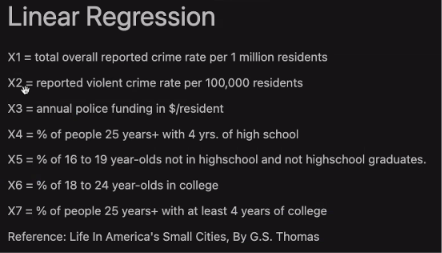

In [4]:
# Dealing with multicollinearity is an important part of feature selection, which will be in our homework.

import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

crime_df = pd.read_csv("crime_data.csv")
crime_df.head()

,X1,X2,X3,X4,X5,X6,X7
0,478,184,40,74,11,31,20
1,494,213,32,72,11,43,18
2,643,347,57,70,18,16,16
3,341,565,31,71,11,25,19
4,773,327,67,72,9,29,24


In [4]:
crime_df.corr()

,X1,X2,X3,X4,X5,X6,X7
X1,1.000000,0.756505,0.533198,-0.135459,0.322519,-0.175224,-0.026283
X2,0.756505,1.000000,0.509339,-0.184445,0.291031,-0.199070,-0.045570
X3,0.533198,0.509339,1.000000,0.120265,0.311526,-0.277475,0.124502
X4,-0.135459,-0.184445,0.120265,1.000000,-0.537162,0.182364,0.681072
X5,0.322519,0.291031,0.311526,-0.537162,1.000000,-0.626953,-0.513958
X6,-0.175224,-0.199070,-0.277475,0.182364,-0.626953,1.000000,0.591663
X7,-0.026283,-0.045570,0.124502,0.681072,-0.513958,0.591663,1.000000


<Axes: >

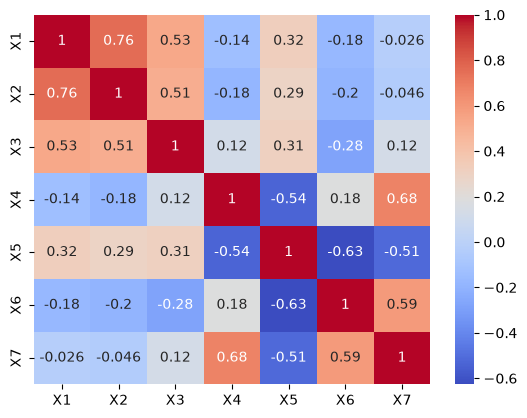

In [7]:
sns.heatmap(crime_df.corr(), annot=True, cmap="coolwarm")

In [8]:
# lower y and CAPITAL X are customary

y = crime_df["X1"]
# X2 and X3 are strongly correlated with X1.
# BUT, X2 and X3 are fairly strongly correlated to each other too, so don't include both here.
# X4 is not strongly correlated with X1, so leave it out, along with X6-7.
X = crime_df[["X2", "X5"]]

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=10)

In [8]:
from sklearn.linear_model import LinearRegression

"""
Linear regression is a class, and we're making an instance of it to fit our training data.
"""

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

y_pred

# Mean squared error
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
print(mse) # This is high as hell dawg

0.16780755697937613


In [ ]:
# Does accuracy matter here? No, because this is regression, not classification.
# R squared:
accuracy_score = lr.score(X_test, y_test)
accuracy_score

0.5675800011202556

In [ ]:
#

print(lr.coef_)
print(lr.intercept_)

# Linear regression equation:
# y = 0.335 * X2 + 8.458 * X5 + 372.960

[0.33541896 8.45822449]
372.9600042839298


In [14]:
# OLS Regression
# OLS = ordinary least squares
# A type of regression that lets you handle interactions as well as features that don't have interactions.
# With OLS regression, you can incorporate features that are correlated with each other.
# This is getting added to our homework since we have more time now. Hooray......

In [2]:
! pip install statsmodels

In [6]:
# Look at statsmodels stuff from her notes. Took some time to get that working.

# Logistic regression
diabetes_df = pd.read_csv("diabetes.csv")
diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
X = diabetes_df.drop("Outcome", axis=1)
y = diabetes_df["Outcome"]

# stratification can be (but isn't always) useful.
# it tries to split the test data into groups that represent
# the distribution of the target variable.
# So it makes sure the groups are representative. You wouldnt want
# all the old people with diabetes in the training set and
# then have all the old people without diabetes in the test set.

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

from sklearn.preprocessing import StandardScaler

# Standardize the data
# Prof wouldn't necessarily use Standard Scaler, but it's an approach. She
# wouldn't use it because it's naive.
scaler = StandardScaler()


In [9]:
# Simplest logistic regression approach
from sklearn.linear_model import LogisticRegression
regression = LogisticRegression(random_state=10)
regression.fit(X_train, y_train)
y_pred = regression.predict(X_test)

from sklearn.metrics import accuracy_score

c:\Users\phoen\anaconda3\envs\data-science-env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
